# Actividad — SVR para consumo energético de edificios
**Aprendizaje Supervisado · Sesión 6 · Regresión con máquinas de vectores de soporte**

**Qué haremos.** En la presentación vimos que SVR controla el error con un **tubo $\varepsilon$-insensible**
en vez de penalizar todos los residuos, y que el **truco del kernel** (lineal, polinomial, RBF) le permite
curvarse sin construir columnas nuevas a mano. Hoy aplicas todo eso a un problema real: predecir el
**consumo eléctrico diario (kWh)** de un edificio a partir del clima y sus características, donde la
relación con la temperatura **no es una línea recta** sino una curva en forma de U.

Este notebook ya está **completo**: el código, sus resultados y las respuestas a cada pregunta ya están
incluidos. No hay nada que llenar ni que entregar; úsalo para leer y repasar los conceptos de la Sesión 6
a tu propio ritmo.


## Parte 0 — Los datos

Cada fila es un edificio-día con 5 variables de entrada: `temperatura_c`, `superficie_m2`, `ocupantes`,
`aislamiento` (0 malo .. 1 excelente) y `fin_semana` (0/1). La salida es `consumo_kwh`. El consumo depende
de forma **no lineal** de la temperatura (sube con frío y con calor, mínimo cerca de los 21°C), y esa
curvatura se vuelve más suave cuanto mejor aislado está el edificio.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

datos = pd.read_csv("consumo_energetico.csv")
FEATS = ["temperatura_c", "superficie_m2", "ocupantes", "aislamiento", "fin_semana"]
X = datos[FEATS].values
y = datos["consumo_kwh"].values

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
kf = KFold(5, shuffle=True, random_state=0)

def rmse(m, X, y):
    return np.sqrt(mean_squared_error(y, m.predict(X)))

print(f"n entrenamiento = {len(Xtr)}   n prueba = {len(Xte)}   variables = {FEATS}")
datos.describe().round(2).T

n entrenamiento = 675   n prueba = 225   variables = ['temperatura_c', 'superficie_m2', 'ocupantes', 'aislamiento', 'fin_semana']


,count,mean,std,min,25%,50%,75%,max
temperatura_c,900.0,18.57,12.79,-4.90,7.88,19.20,29.50,40.00
superficie_m2,900.0,145.19,51.96,48.00,107.90,137.45,173.42,420.00
ocupantes,900.0,4.45,2.31,1.00,2.00,4.00,6.00,8.00
aislamiento,900.0,0.50,0.21,0.04,0.33,0.52,0.67,0.98
fin_semana,900.0,0.50,0.50,0.00,0.00,0.00,1.00,1.00
consumo_kwh,900.0,29.23,11.19,8.03,20.76,27.22,36.33,75.05


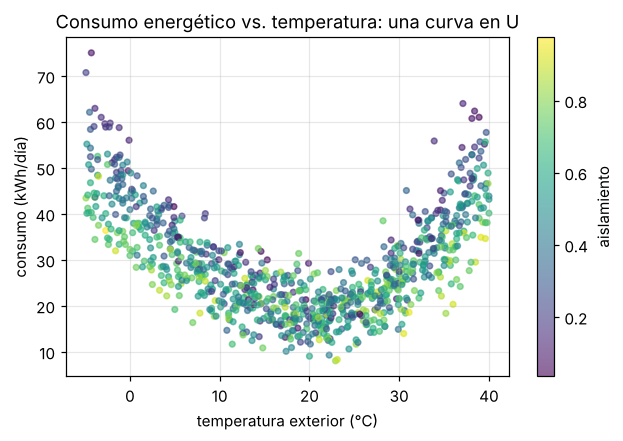

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 4))
sca = ax.scatter(datos["temperatura_c"], datos["consumo_kwh"], c=datos["aislamiento"], cmap="viridis", s=14, alpha=0.6)
fig.colorbar(sca, ax=ax, label="aislamiento")
ax.set_xlabel("temperatura exterior (°C)"); ax.set_ylabel("consumo (kWh/día)")
ax.set_title("Consumo energético vs. temperatura: una curva en U");

✏️ **Pregunta 0.1.** Mirando la gráfica: ¿por qué un modelo lineal (una sola recta) no podría ajustar bien esta relación? ¿En qué rango de temperatura el consumo es más bajo?

> ✅ **Respuesta (solucionario)**
>
> Una recta solo puede subir o solo bajar; no puede primero bajar y luego subir. Aquí el consumo **baja** conforme la temperatura sube de $-5$ a $\approx 20$°C, y luego **vuelve a subir** hasta los 40°C: es una curva en **U**, no monótona. Cualquier recta que se ajuste bien a un lado de la U quedará muy mal del otro lado. El consumo es más bajo alrededor de los **20°C**, la temperatura de confort donde no se necesita ni calefacción ni aire acondicionado.

## Parte 1 — SVR lineal como punto de partida  *(presentación A4, C1)*

Ajustamos un SVR con `kernel="linear"`. El escalador va dentro del `Pipeline` porque SVR usa distancias/productos
punto, y son sensibles a la escala de cada variable.

In [3]:
lineal = make_pipeline(StandardScaler(), SVR(kernel="linear", C=10, epsilon=1.0)).fit(Xtr, ytr)
print(f"SVR lineal   RMSE entrenamiento = {rmse(lineal, Xtr, ytr):.2f}    RMSE prueba = {rmse(lineal, Xte, yte):.2f}")
print(f"Vectores de soporte: {lineal[-1].support_.shape[0]} de {len(Xtr)}")

SVR lineal   RMSE entrenamiento = 9.65    RMSE prueba = 11.54
Vectores de soporte: 619 de 675


✏️ **Pregunta 1.1.** El RMSE del SVR lineal, ¿es alto o bajo en comparación con la escala de `consumo_kwh` (revisa la tabla de la Parte 0)? ¿Por qué un kernel lineal tiene este problema aquí, si recordamos la Parte 0?

> ✅ **Respuesta (solucionario)**
>
> El RMSE de prueba del SVR lineal es **11.54 kWh/día**, altísimo frente a una media de consumo de **≈29 kWh/día** y una desviación estándar de **≈11 kWh/día**: el error es casi tan grande como la variabilidad total de los datos, es decir, el modelo apenas hace mejor que predecir siempre el promedio. La razón es la misma que en la Parte 0: el kernel lineal solo puede trazar un hiperplano, y la relación con la temperatura es una curva en U que ningún hiperplano puede seguir.

## Parte 2 — SVR con kernel RBF  *(presentación C1–C2)*

Repetimos con `kernel="rbf"` y los hiperparámetros **por defecto** de scikit-learn (sin ajustar nada todavía).

In [4]:
rbf_defecto = make_pipeline(StandardScaler(), SVR(kernel="rbf")).fit(Xtr, ytr)
print(f"SVR RBF (por defecto)  RMSE entrenamiento = {rmse(rbf_defecto, Xtr, ytr):.2f}    RMSE prueba = {rmse(rbf_defecto, Xte, yte):.2f}")
print(f"Hiperparámetros usados: C={rbf_defecto[-1].C}, epsilon={rbf_defecto[-1].epsilon}, gamma={rbf_defecto[-1].gamma}")
print(f"Vectores de soporte: {rbf_defecto[-1].support_.shape[0]} de {len(Xtr)}")

SVR RBF (por defecto)  RMSE entrenamiento = 5.63    RMSE prueba = 6.50
Hiperparámetros usados: C=1.0, epsilon=0.1, gamma=scale
Vectores de soporte: 658 de 675


✏️ **Pregunta 2.1.** Compara el RMSE de prueba del RBF por defecto contra el del SVR lineal de la Parte 1. ¿Confirma esto la idea de la presentación sobre por qué el kernel lineal falla aquí?

> ✅ **Respuesta (solucionario)**
>
> El RBF con hiperparámetros por defecto da RMSE de prueba **6.50**, casi la **mitad** del lineal (**11.54**), aun sin ajustar nada. Confirma la idea de la presentación: el problema del kernel lineal no es de optimización ($C$ o $\varepsilon$ mal elegidos) sino de **forma**: no puede curvarse. Apenas se permite curvatura (RBF), el error baja mucho incluso con hiperparámetros genéricos; más adelante, afinando $C$, $\varepsilon$ y $\gamma$, baja todavía más (Parte 5).

## Parte 3 — Efecto de $C$ y de $\varepsilon$  *(presentación B4–B6)*

Primero variamos $C$ dejando $\varepsilon=1.0$ fijo; luego variamos $\varepsilon$ dejando $C=50$ fijo.
En ambos casos usamos kernel RBF con `gamma="scale"`.

      C  rmse_train  rmse_test  vectores_soporte
   0.01       10.94      12.04               620
   0.10        9.99      11.11               620
   1.00        5.68       6.61               542
  10.00        2.78       3.70               474
 100.00        1.93       3.05               479
1000.00        1.67       3.22               499


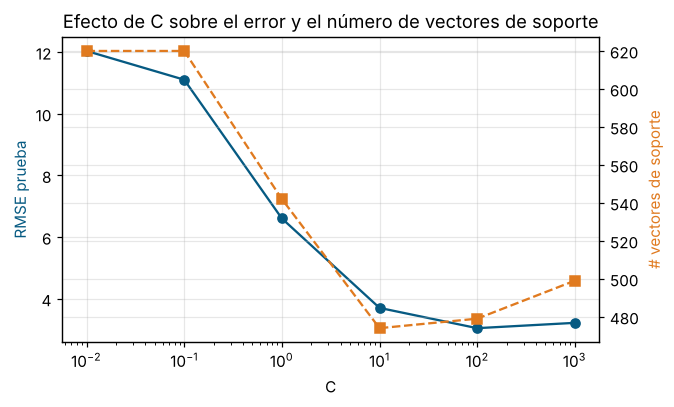

In [5]:
valores_C = [0.01, 0.1, 1, 10, 100, 1000]
filas_c = []
for C in valores_C:
    m = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=C, epsilon=1.0)).fit(Xtr, ytr)
    filas_c.append({"C": C, "rmse_train": rmse(m, Xtr, ytr), "rmse_test": rmse(m, Xte, yte),
                     "vectores_soporte": int(m[-1].support_.shape[0])})
tabla_c = pd.DataFrame(filas_c)
print(tabla_c.round(2).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(6.3, 3.6))
ax1.plot(tabla_c["C"], tabla_c["rmse_test"], "o-", color="#065A82", label="RMSE prueba")
ax1.set_xscale("log"); ax1.set_xlabel("C"); ax1.set_ylabel("RMSE prueba", color="#065A82")
ax2 = ax1.twinx()
ax2.plot(tabla_c["C"], tabla_c["vectores_soporte"], "s--", color="#E07A1F", label="# vect. soporte")
ax2.set_ylabel("# vectores de soporte", color="#E07A1F")
ax1.set_title("Efecto de C sobre el error y el número de vectores de soporte");

In [6]:
valores_eps = [0.1, 0.5, 1, 2, 4, 8]
filas_e = []
for eps in valores_eps:
    m = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=50, epsilon=eps)).fit(Xtr, ytr)
    filas_e.append({"epsilon": eps, "rmse_train": rmse(m, Xtr, ytr), "rmse_test": rmse(m, Xte, yte),
                     "vectores_soporte": int(m[-1].support_.shape[0])})
tabla_e = pd.DataFrame(filas_e)
print(tabla_e.round(2).to_string(index=False))

 epsilon  rmse_train  rmse_test  vectores_soporte
     0.1        2.08       3.25               653
     0.5        2.04       3.17               578
     1.0        2.05       3.10               484
     2.0        2.16       3.14               306
     4.0        2.56       3.48               127
     8.0        3.98       5.11                51


✏️ **Pregunta 3.1.** (a) ¿Qué le pasa al RMSE de prueba con $C$ muy chica? ¿Y con $C$ muy grande, el RMSE de prueba sigue mejorando o empieza a empeorar? (b) ¿Cómo cambia el número de vectores de soporte al subir $C$? (c) ¿Cómo cambia el número de vectores de soporte al subir $\varepsilon$, y por qué tiene sentido con lo que viste en la presentación (parte B)?

> ✅ **Respuesta (solucionario)**
>
> **(a)** Con $C=0.01$ el RMSE de prueba es **12.04**, casi tan malo como el modelo lineal: el modelo tolera tantas violaciones que apenas aprende. Al subir $C$ el error baja hasta un mínimo en **$C=100$ (RMSE 3.05)**; subir más a $C=1000$ ya **empeora** levemente (RMSE 3.22, aunque el error de entrenamiento sigue bajando a 1.67): es la firma del sobreajuste, igual que vimos con $\alpha$ muy chico en Ridge/Lasso pero al revés.
>
> **(b)** De $C=0.01$ a $C=10$ el número de vectores de soporte **baja** (de 620 a 474): el modelo deja de tratar a casi todos los puntos como violaciones. De $C=10$ en adelante se mantiene parecido (≈474–499): ya persigue un número similar de puntos difíciles, solo que con más fuerza.
>
> **(c)** Al subir $\varepsilon$ de 0.1 a 8, los vectores de soporte **bajan** de 653 a 51 (de 675 totales): un tubo más ancho absorbe más puntos sin penalizarlos, así que menos puntos quedan fuera violando el tubo. Esto coincide exactamente con la Sesión 6, parte B: $\varepsilon$ grande = tubo ancho = pocos vectores de soporte, pero también un modelo más plano que puede subajustar (el RMSE empieza a subir otra vez en $\varepsilon=4$ y $8$).

## Parte 4 — Comparación de kernels: lineal, polinomial y RBF  *(presentación C3–C4)*

Ahora comparamos los tres kernels **con el mismo protocolo**: mismo $C$, mismo $\varepsilon$, mismos
conjuntos de entrenamiento y prueba.

 kernel  rmse_train  rmse_test  vectores_soporte
 lineal        9.65      11.54               619
poly(3)        2.24       2.37               478
    rbf        2.05       3.10               484


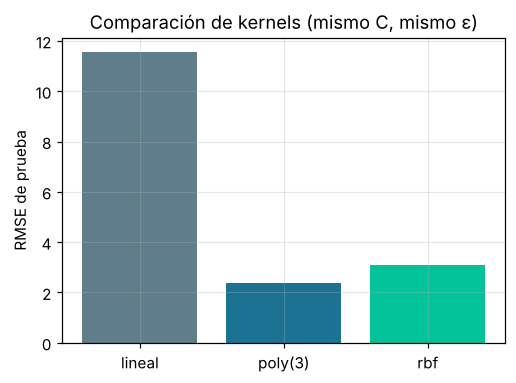

In [7]:
modelos4 = {
    "lineal": SVR(kernel="linear", C=50, epsilon=1.0),
    "poly(3)": SVR(kernel="poly", degree=3, coef0=1, C=50, epsilon=1.0),
    "rbf": SVR(kernel="rbf", C=50, epsilon=1.0),
}
filas4 = []
for nombre, svr in modelos4.items():
    m = make_pipeline(StandardScaler(), svr).fit(Xtr, ytr)
    filas4.append({"kernel": nombre, "rmse_train": rmse(m, Xtr, ytr), "rmse_test": rmse(m, Xte, yte),
                    "vectores_soporte": int(m[-1].support_.shape[0])})
tabla4 = pd.DataFrame(filas4)
print(tabla4.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.bar(tabla4["kernel"], tabla4["rmse_test"], color=["#607D8B", "#1C7293", "#02C39A"])
ax.set_ylabel("RMSE de prueba"); ax.set_title("Comparación de kernels (mismo C, mismo ε)");

✏️ **Pregunta 4.1.** (a) ¿Qué kernel tiene el peor RMSE de prueba y por qué (relaciónalo con la Parte 0)? (b) ¿Qué tan parecidos son poly(3) y RBF aquí? (c) ¿Cuál de los dos usa menos vectores de soporte?

> ✅ **Respuesta (solucionario)**
>
> **(a)** El kernel **lineal** es, por mucho, el peor (RMSE 11.54 contra 2.37 y 3.10 de los otros dos): como en la Parte 0 y 1, no puede seguir la curva en U del consumo contra la temperatura.
>
> **(b)** **poly(3)** (RMSE 2.37) y **RBF** (RMSE 3.10) son comparables y mucho mejores que el lineal; aquí poly(3) incluso queda un poco por debajo de RBF con estos hiperparámetros fijos (antes de ajustar $\gamma$ con `GridSearchCV` en la Parte 5, donde RBF termina ganando con 2.52).
>
> **(c)** **poly(3)** usa menos vectores de soporte (**478** contra **484** de RBF), aunque la diferencia es pequeña con este $C$ y $\varepsilon$.

## Parte 5 — Ajuste de $C$, $\varepsilon$ y $\gamma$ con `GridSearchCV`  *(presentación D1–D2)*

Buscamos los tres hiperparámetros del kernel RBF **juntos**, con validación cruzada de 5 particiones.
La rejilla es moderada para que la celda no tarde demasiado; en un proyecto real valdría la pena
una rejilla más fina alrededor del óptimo encontrado aquí.

In [8]:
pipe_rbf = make_pipeline(StandardScaler(), SVR(kernel="rbf"))
malla = {"svr__C": np.logspace(0, 3, 6), "svr__gamma": np.logspace(-2, 1, 6), "svr__epsilon": [0.5, 1.0, 2.0]}
bus = GridSearchCV(pipe_rbf, malla, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
bus.fit(Xtr, ytr)
print("Mejores hiperparámetros:", bus.best_params_)
print(f"RMSE de validación = {-bus.best_score_:.2f}    RMSE de prueba = {rmse(bus, Xte, yte):.2f}")
print(f"Vectores de soporte: {bus.best_estimator_[-1].support_.shape[0]} de {len(Xtr)}")

Mejores hiperparámetros: {'svr__C': np.float64(1000.0), 'svr__epsilon': 1.0, 'svr__gamma': np.float64(0.039810717055349734)}
RMSE de validación = 2.55    RMSE de prueba = 2.52
Vectores de soporte: 468 de 675


✏️ **Pregunta 5.1.** (a) ¿Qué combinación de $C$, $\gamma$ y $\varepsilon$ eligió `GridSearchCV`? (b) ¿Mejora el RMSE de prueba frente al RBF con hiperparámetros por defecto de la Parte 2? (c) Si tuvieras más tiempo de cómputo, ¿cómo ajustarías la rejilla para refinar la búsqueda alrededor de lo encontrado?

> ✅ **Respuesta (solucionario)**
>
> **(a)** `GridSearchCV` eligió **$C=1000$, $\varepsilon=1.0$, $\gamma\approx 0.040$** (RMSE de validación 2.55, de prueba 2.52).
>
> **(b)** Sí, mejora bastante: de **RMSE 6.50** (RBF por defecto, Parte 2) a **RMSE 2.52** —menos de la mitad— solo por buscar mejor los tres hiperparámetros.
>
> **(c)** $C$ quedó en el **extremo superior** de la rejilla (1000), así que valdría la pena extender la búsqueda hacia valores aún más grandes (por ejemplo hasta $10^4$) para confirmar que el óptimo no sigue subiendo; para $\gamma$ conviene una rejilla más fina alrededor de 0.01–0.1, y para $\varepsilon$ alrededor de 0.5–1.5.

## Parte 6 — Comparación final contra los modelos de sesiones anteriores  *(presentación E2)*

Ponemos el mejor SVR (de la Parte 5) a competir contra **OLS**, **Ridge** y **Lasso** (con validación
cruzada para su hiperparámetro), todos evaluados en el **mismo** conjunto de prueba.

In [9]:
modelos6 = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 50), cv=kf)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-3, 2, 60), cv=kf, max_iter=100000)),
    "SVR lineal": make_pipeline(StandardScaler(), SVR(kernel="linear", C=50, epsilon=1.0)),
    "SVR RBF (GridSearchCV)": bus.best_estimator_,
}
filas6 = []
for nombre, m in modelos6.items():
    if nombre != "SVR RBF (GridSearchCV)":
        m.fit(Xtr, ytr)
    filas6.append({"modelo": nombre, "rmse_prueba": round(rmse(m, Xte, yte), 3)})
comparacion = pd.DataFrame(filas6).sort_values("rmse_prueba").reset_index(drop=True)
print(comparacion.to_string(index=False))

entregable = comparacion.copy()
entregable["comentario"] = "✏️ escribe tu comentario"
entregable.to_csv("entregable_unidad6.csv", index=False)
entregable

                modelo  rmse_prueba
SVR RBF (GridSearchCV)        2.517
                 Ridge       11.132
                 Lasso       11.155
                   OLS       11.155
            SVR lineal       11.542


,modelo,rmse_prueba,comentario
0,SVR RBF (GridSearchCV),2.517,✏️ escribe tu comentario
1,Ridge,11.132,✏️ escribe tu comentario
2,Lasso,11.155,✏️ escribe tu comentario
3,OLS,11.155,✏️ escribe tu comentario
4,SVR lineal,11.542,✏️ escribe tu comentario


✏️ **Pregunta 6.1.** (a) Ordena los modelos de mejor a peor en prueba. ¿Cuánto gana el mejor SVR sobre el mejor modelo lineal (OLS/Ridge/Lasso)? (b) ¿Por qué Ridge y Lasso no logran capturar la curva en U, aunque regularicen bien? (c) Esta comparación viene de **un solo** reparto entrenamiento/prueba: ¿qué harías para confiar más en la diferencia entre SVR y los modelos lineales?

> ✅ **Respuesta (solucionario)**
>
> **(a)** De mejor a peor: **SVR RBF (GridSearchCV) 2.52** $\ll$ **Ridge 11.13** $\approx$ **Lasso 11.16** $\approx$ **OLS 11.16** $<$ **SVR lineal 11.54**. El mejor SVR reduce el error a menos de la **cuarta parte** del mejor modelo lineal (Ridge): una mejora enorme.
>
> **(b)** Ridge y Lasso regularizan el **tamaño** de los coeficientes de un modelo que sigue siendo **lineal** en las variables originales; ninguna cantidad de regularización le da a una recta la capacidad de curvarse en U. Regularizar ayuda contra el sobreajuste, no contra la forma equivocada del modelo.
>
> **(c)** Repetiría la comparación con **varios repartos** entrenamiento/prueba (o validación cruzada anidada) y reportaría el RMSE promedio con su variación, en vez de confiar en un solo `random_state=42`.

**Visualizando el ajuste.** La tabla ya dice qué tan bien generaliza cada modelo; esta gráfica muestra *cómo se ve* ese ajuste en el conjunto de prueba: cada punto es un edificio-día, el eje $x$ es su consumo real y el eje $y$ el consumo que predijo el modelo. Entre más pegados estén los puntos a la diagonal (predicción = realidad), mejor el ajuste.


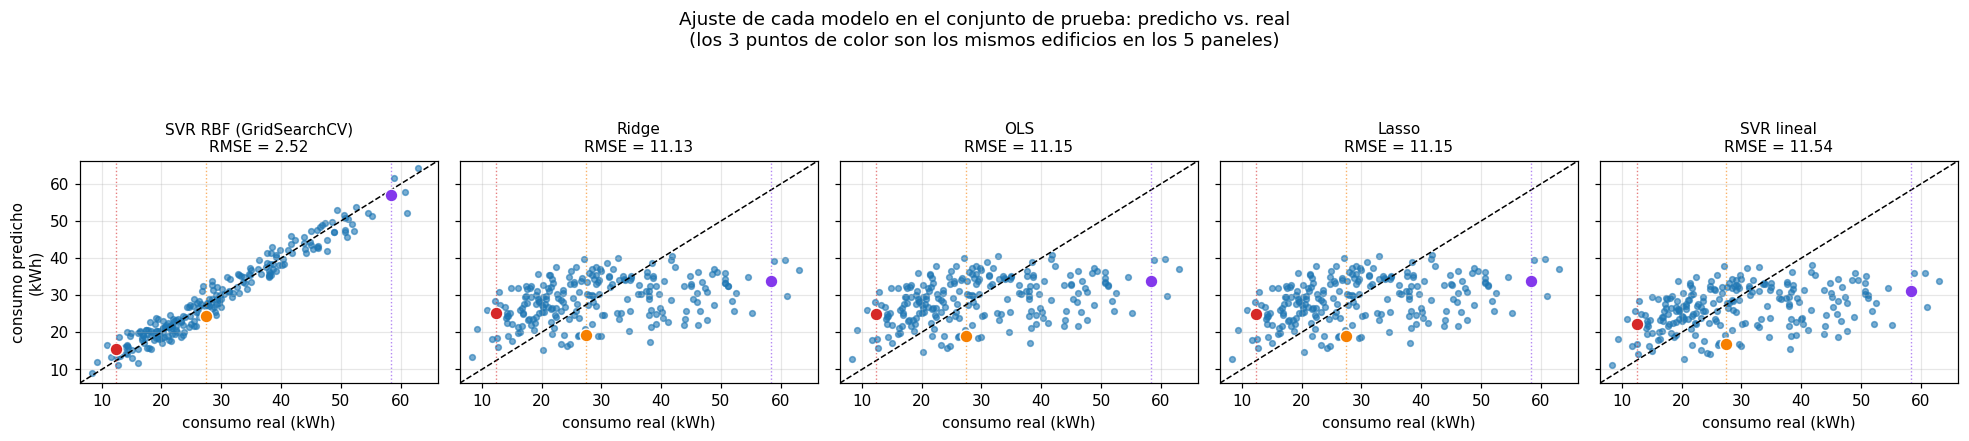

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharex=True, sharey=True)
preds_all = {n: modelos6[n].predict(Xte) for n in modelos6}
lo = min(yte.min(), *[p.min() for p in preds_all.values()]) - 2
hi = max(yte.max(), *[p.max() for p in preds_all.values()]) + 2

# tres edificios de referencia: mismo índice (mismo dato real) en los 5 paneles,
# para ver cómo cambia la predicción de cada modelo sobre el MISMO edificio
idx_ref = np.argsort(yte)[[5, len(yte)//2, -5]]
colores_ref = ["#D62828", "#F77F00", "#8338EC"]

for ax, nombre in zip(axes, comparacion["modelo"]):
    pred = preds_all[nombre]
    rmse_m = comparacion.loc[comparacion["modelo"] == nombre, "rmse_prueba"].values[0]
    ax.scatter(yte, pred, s=14, alpha=0.6)
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    for i, color in zip(idx_ref, colores_ref):
        ax.axvline(yte[i], color=color, ls=":", lw=0.9, alpha=0.6)
        ax.scatter(yte[i], pred[i], color=color, s=70, zorder=5, edgecolor="white", linewidth=0.9)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(f"{nombre}\nRMSE = {rmse_m:.2f}", fontsize=10)
    ax.set_xlabel("consumo real (kWh)")
axes[0].set_ylabel("consumo predicho\n(kWh)")
fig.suptitle("Ajuste de cada modelo en el conjunto de prueba: predicho vs. real\n"
             "(los 3 puntos de color son los mismos edificios en los 5 paneles)", y=1.1)
plt.tight_layout()
plt.show()

## Parte 8 — Recomendación final

✏️ **Pregunta 8.1.** Redacta una recomendación breve (6 a 8 líneas) para un colega que va a modelar el
consumo energético de otro conjunto de edificios: qué kernel usarías y por qué, qué pasos seguirías
(escalado, validación cruzada, elección de $C$/$\varepsilon$/$\gamma$), qué mejora de RMSE esperarías
frente a un modelo lineal **en datos como estos**, qué limitaciones tiene SVR (costo computacional,
interpretabilidad frente a un modelo lineal) y qué cuidados tomaste para no engañarte (conjunto de
prueba, escalado dentro del pipeline).

> ✅ **Respuesta (solucionario)**
>
> Empezaría con un kernel **RBF** (o poly si sospechas una curva más suave y de bajo grado): en estos
> datos la relación con la temperatura es una **U**, no monótona, y ningún kernel lineal puede seguirla
> (RMSE 11.54 contra 2.5–3.1 de RBF/poly). Metería `StandardScaler` **dentro del `Pipeline`**, antes del
> `SVR`, porque RBF mide distancias $\lVert x-x'\rVert$ y una sola variable con escala grande (aquí,
> `superficie_m2`) dominaría el resto si no se escala. Ajustaría $C$, $\varepsilon$ y $\gamma$ **juntos**
> con `GridSearchCV` y validación cruzada de 5 particiones, nunca a mano ni mirando el conjunto de
> prueba. Frente a un modelo lineal (OLS/Ridge/Lasso, RMSE $\approx$11) esperaría una mejora de **4 a 5
> veces** en datos con esta forma de U. Las limitaciones de SVR: es más caro de entrenar que un modelo
> lineal (sobre todo al buscar hiperparámetros en rejilla) y mucho menos interpretable (no hay
> coeficientes que leer, solo vectores de soporte). Por último, separaría **un solo** conjunto de prueba
> que no toco hasta el final, y usaría validación cruzada solo sobre el conjunto de entrenamiento para
> elegir hiperparámetros, de modo que el RMSE de prueba reportado sea una estimación honesta.
